# Plot Vectors In Normalized Coordinate Space

This notebook plots polarization vectors using coordinates normalized per file, so each file is shown in its own relative coordinate space.

Normalization used for each file:
- `X_norm = (X - X_min) / (X_max - X_min)`
- `Y_norm = (Y - Y_min) / (Y_max - Y_min)`

In [424]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import zipfile
import xml.etree.ElementTree as ET

#BASE_DIR = Path(r"e:/Work/SOKs/TIFFS_publication/Fig SX_emergence-cellular/polarisation/script")
BASE_DIR = Path.cwd()  # run from Figure_S7/

# Input files grouped by construct
sok1_csv_files = [
    BASE_DIR / r"SOK1/young emerged/polarisation SOK1 timelapse1_pos.csv",
    BASE_DIR / r"SOK1/young emerged/polarisation SOK1 timelapse 2_pos.csv",
    BASE_DIR / r"SOK1/young emerged/polarisation SOK1 timelapse3_pos.csv",
    BASE_DIR / r"SOK1/young emerged/polarisation SOK1 timelapse4_pos.csv",
]

sok2_csv_files = [
    BASE_DIR / r"SOK2/young emerged/polarisation t32 SOK2_mirrored.csv",
    BASE_DIR / r"SOK2/young emerged/polarisation t24 SOK2_4_mirrored.csv",
    BASE_DIR / r"SOK2/young emerged/polarisation SOK2 timelapse 2.csv",
]

sok5_csv_files = [
    BASE_DIR / r"SOK5/young emerged/polarisation SOK5 timelapse 1_mirrored_pos.csv",
    BASE_DIR / r"SOK5/young emerged/polarisation SOK5 timelapse 2_pos.csv",
    BASE_DIR / r"SOK5/young emerged/polarisation SOK5 timelapse 3_pos.csv",
]

# Plot style
vector_cols = ("xMax", "yMax")
quiver_scale = 20
quiver_width = 0.002
tissue_colors = {"V": "#B1B1B1", "G": "#383838", "A": "#000000"}
default_color = "black"
mt_color = "#2ca25f"

# Global multiplier for SOK vector lengths (1.35 = 35% larger)
use_sok_vector_length_multiplier = False
sok_vector_length_multiplier = 1.35

# Optional intensity-based vector scaling
use_maxsignal_scaling = False
maxsignal_col = "signalMax"
maxsignal_power = 1.0

# Toggle to show only V/A/G tissues
show_only_vag = True

# MT plotting options
use_mt_intensity_correction = False
mt_raw_anisotropy_col = "anisotropy"
# Update this if your corrected column name differs in the MT Excel file.
mt_corrected_anisotropy_col = "anisotropy intensity-corrected"
# If False, MT line lengths are uniform (no anisotropy/intensity scaling).
use_mt_anisotropy_length_scaling = False
# Global MT vector length multiplier (0.40 = 60% shorter than previous length)
mt_vector_length_multiplier = 0.2

# SVG export settings
save_svg = True
output_dir = BASE_DIR / "figures" / "svg"
output_dir.mkdir(parents=True, exist_ok=True)

In [425]:
def _prepare_mt_stage_space(mt_df):
    out = mt_df.copy()

    x_series = None
    x_source = first_existing_column(out, ["x-coordinate of ROI centre", "X position", "X", "x"])
    width_col = first_existing_column(out, ["image width", "width"])
    if x_source is not None and width_col is not None:
        x_series = pd.to_numeric(out[x_source], errors="coerce") / pd.to_numeric(out[width_col], errors="coerce")
    elif "X position" in out.columns:
        x_series = pd.to_numeric(out["X position"], errors="coerce")

    y_series = None
    if "Y position regular correct position zoom-corrected" in out.columns:
        y_series = pd.to_numeric(out["Y position regular correct position zoom-corrected"], errors="coerce")
    if y_series is None or y_series.notna().sum() == 0:
        y_source = first_existing_column(out, ["y-coordinate of ROI centre", "Y", "y"])
        height_col = first_existing_column(out, ["image height", "height"])
        zoom_col = first_existing_column(out, ["zoom correction"])
        if y_source is not None and height_col is not None:
            y_norm = pd.to_numeric(out[y_source], errors="coerce") / pd.to_numeric(out[height_col], errors="coerce")
            if zoom_col is not None:
                zoom = pd.to_numeric(out[zoom_col], errors="coerce")
                y_series = (1.0 - y_norm) * zoom + ((1.0 - zoom) / 2.0)
            else:
                y_series = 1.0 - y_norm

    out["X_plot"] = x_series
    out["Y_plot"] = y_series
    return out


mt_color = default_color

In [426]:
def load_and_normalize_xy(csv_path, x_col="X", y_col="Y"):

    df = pd.read_csv(csv_path).copy()

    required = [x_col, y_col, vector_cols[0], vector_cols[1]]

    missing = [c for c in required if c not in df.columns]

    if missing:

        raise ValueError(f"{csv_path} missing columns: {missing}")



    plot_df = df.dropna(subset=required).copy()

    x_min, x_max = plot_df[x_col].min(), plot_df[x_col].max()

    y_min, y_max = plot_df[y_col].min(), plot_df[y_col].max()



    x_span = x_max - x_min

    y_span = y_max - y_min

    if x_span == 0 or y_span == 0:

        raise ValueError(

            f"{csv_path} has zero span in X or Y (x_span={x_span}, y_span={y_span})"

        )



    plot_df["X_norm"] = (plot_df[x_col] - x_min) / x_span

    plot_df["Y_norm"] = (plot_df[y_col] - y_min) / y_span

    return plot_df





def _vector_magnitude_scale_from_files(file_list, quantile=0.95):

    ux, uy = vector_cols

    magnitudes = []



    for csv_path in file_list:

        csv_path = Path(csv_path)

        if not csv_path.exists():

            continue



        df = pd.read_csv(csv_path)

        required = [ux, uy]

        if not set(required).issubset(df.columns):

            continue



        vec_df = df[required].dropna()

        if vec_df.empty:

            continue



        mags = np.hypot(vec_df[ux].to_numpy(), vec_df[uy].to_numpy())

        if mags.size:

            magnitudes.append(mags)



    if not magnitudes:

        return 1.0



    all_mags = np.concatenate(magnitudes)

    scale = float(np.quantile(all_mags, quantile))

    return scale if scale > 0 else 1.0





def _stage_vector_scale(stage_groups, quantile=0.95):

    stage_files = [csv_path for _, files in stage_groups for csv_path in files]

    return _vector_magnitude_scale_from_files(stage_files, quantile=quantile)





def _maxsignal_factor(plot_df):

    if not use_maxsignal_scaling or maxsignal_col not in plot_df.columns:

        return pd.Series(1.0, index=plot_df.index)



    signal = pd.to_numeric(plot_df[maxsignal_col], errors="coerce").fillna(0).clip(lower=0)

    signal_max = signal.max()

    if signal_max <= 0:

        return pd.Series(1.0, index=plot_df.index)



    return (signal / signal_max) ** maxsignal_power





def plot_sok_group(

    ax,

    group_name,

    file_list,

    vector_length_scale=1.0,

):

    ux, uy = vector_cols

    included_files = []

    n_cells = 0

    if vector_length_scale <= 0:

        vector_length_scale = 1.0



    for csv_path in file_list:

        csv_path = Path(csv_path)

        if not csv_path.exists():

            print(f"Skipping missing file: {csv_path}")

            continue



        plot_df = load_and_normalize_xy(csv_path)

        included_files.append(csv_path.name)

        n_cells += len(plot_df)



        signal_factor = _maxsignal_factor(plot_df)

        length_multiplier = sok_vector_length_multiplier if use_sok_vector_length_multiplier else 1.0

        u_plot = (plot_df[ux] / vector_length_scale) * signal_factor * length_multiplier

        v_plot = (plot_df[uy] / vector_length_scale) * signal_factor * length_multiplier



        tissue_series = (

            plot_df["Tissue"].fillna("").astype(str).str.strip()

            if "Tissue" in plot_df.columns

            else pd.Series([""] * len(plot_df), index=plot_df.index)

        )



        for tissue, color in tissue_colors.items():

            m = tissue_series == tissue

            if m.any():

                ax.quiver(

                    plot_df.loc[m, "X_norm"],

                    plot_df.loc[m, "Y_norm"],

                    u_plot.loc[m],

                    v_plot.loc[m],

                    angles="xy",

                    scale_units="xy",

                    scale=quiver_scale,

                    width=quiver_width,

                    alpha=0.85,

                    color=color,

                    headlength=0,

                    headwidth=0,

                    headaxislength=0,

                )



        if not show_only_vag:

            m_other = ~tissue_series.isin(list(tissue_colors.keys()))

            if m_other.any():

                ax.quiver(

                    plot_df.loc[m_other, "X_norm"],

                    plot_df.loc[m_other, "Y_norm"],

                    u_plot.loc[m_other],

                    v_plot.loc[m_other],

                    angles="xy",

                    scale_units="xy",

                    scale=quiver_scale,

                    width=quiver_width,

                    alpha=0.5,

                    color=default_color,

                    headlength=0,

                    headwidth=0,

                    headaxislength=0,

                )



    ax.set_xlim(-0.05, 1.05)

    ax.set_ylim(-0.05, 1.05)

    ax.set_aspect("equal", adjustable="box")

    ax.grid(True, linestyle="--", alpha=0.25)

    ax.set_title(group_name)

    ax.set_xlabel("Normalized X")



    return included_files, n_cells





def _normalize_series(series):

    s_min = series.min()

    s_max = series.max()

    s_span = s_max - s_min

    if s_span == 0:

        return pd.Series([0.5] * len(series), index=series.index)

    return (series - s_min) / s_span





def _normalize_col_name(name):

    # Ignore spaces, punctuation, and case when matching user-provided column names.

    return ''.join(ch for ch in str(name).lower() if ch.isalnum())





def _resolve_column_name(mt_df, requested_name):

    if requested_name in mt_df.columns:

        return requested_name



    requested_norm = _normalize_col_name(requested_name)

    for col in mt_df.columns:

        if _normalize_col_name(col) == requested_norm:

            return col



    return None





def first_existing_column(frame, candidates):

    for col in candidates:

        if col in frame.columns:

            return col

    return None





def tissue_series_from_frame(frame):

    tissue_col = first_existing_column(frame, ["tissue", "Tissue"])

    if tissue_col is None:

        return pd.Series([""] * len(frame), index=frame.index)

    return frame[tissue_col].fillna("").astype(str).str.strip().str.upper()





def _tissue_color_for_value(value):

    key = str(value).strip().upper() if value is not None else ""

    return tissue_colors.get(key, default_color)





def _prepare_mt_stage_space(mt_df):

    out = mt_df.copy()



    x_series = None

    if "X position" in out.columns:

        x_series = pd.to_numeric(out["X position"], errors="coerce")

    if x_series is None or x_series.notna().sum() == 0:

        x_source = first_existing_column(out, ["x-coordinate of ROI centre", "X", "x"])

        width_col = first_existing_column(out, ["image width", "width"])

        if x_source is not None and width_col is not None:

            x_series = pd.to_numeric(out[x_source], errors="coerce") / pd.to_numeric(out[width_col], errors="coerce")



    y_series = None

    if "Y position regular correct position zoom-corrected" in out.columns:

        y_series = pd.to_numeric(out["Y position regular correct position zoom-corrected"], errors="coerce")

    if y_series is None or y_series.notna().sum() == 0:

        y_source = first_existing_column(out, ["y-coordinate of ROI centre", "Y", "y"])

        height_col = first_existing_column(out, ["image height", "height"])

        zoom_col = first_existing_column(out, ["zoom correction"])

        if y_source is not None and height_col is not None:

            y_norm = pd.to_numeric(out[y_source], errors="coerce") / pd.to_numeric(out[height_col], errors="coerce")

            if zoom_col is not None:

                zoom = pd.to_numeric(out[zoom_col], errors="coerce")

                y_series = (1.0 - y_norm) * zoom + ((1.0 - zoom) / 2.0)

            else:

                y_series = 1.0 - y_norm



    out["X_plot"] = x_series

    out["Y_plot"] = y_series

    return out





def select_mt_anisotropy_column(mt_df):

    resolved_raw = _resolve_column_name(mt_df, mt_raw_anisotropy_col)

    resolved_corrected = _resolve_column_name(mt_df, mt_corrected_anisotropy_col)



    if use_mt_intensity_correction and resolved_corrected is not None:

        return resolved_corrected

    if resolved_raw is not None:

        if use_mt_intensity_correction:

            print(

                f"MT corrected anisotropy column not found ('{mt_corrected_anisotropy_col}'); "

                f"falling back to '{resolved_raw}'."

            )

        return resolved_raw

    raise ValueError(

        "No usable MT anisotropy column found. "

        f"Checked: '{mt_corrected_anisotropy_col}' and '{mt_raw_anisotropy_col}'. Available columns: {list(mt_df.columns)}"

    )





def _expand_repeated_text(cell):

    repeat = int(cell.attrib.get("{urn:oasis:names:tc:opendocument:xmlns:table:1.0}number-columns-repeated", "1"))

    p = cell.find("{urn:oasis:names:tc:opendocument:xmlns:text:1.0}p")

    value = p.text if p is not None else ""

    if value is None:

        value = ""

    return [value] * repeat





def load_mt_pr_ods_relative(ods_path):

    ods_path = Path(ods_path)

    with zipfile.ZipFile(ods_path, "r") as zf:

        with zf.open("content.xml") as f:

            root = ET.parse(f).getroot()



    table_ns = "{urn:oasis:names:tc:opendocument:xmlns:table:1.0}"

    all_rows = root.findall(f".//{table_ns}table-row")



    parsed_rows = []

    for row in all_rows:

        values = []

        for cell in row.findall(f"{table_ns}table-cell"):

            values.extend(_expand_repeated_text(cell))

        if len(values) >= 7:

            parsed_rows.append(values)



    if not parsed_rows:

        return pd.DataFrame(columns=["X position", "Y position", "average fibril orientation", "anisotropy", "tissue"])



    # MT-PR row layout from ODS content: [file, cell_id, y, x, area, angle_deg, anisotropy, tissue, ...]

    mt_df = pd.DataFrame(parsed_rows)

    mt_df = mt_df.rename(

        columns={

            2: "Y position",

            3: "X position",

            5: "average fibril orientation",

            6: "anisotropy",

            7: "tissue",

        }

    )



    keep_cols = ["X position", "Y position", "average fibril orientation", "anisotropy", "tissue"]

    mt_df = mt_df[keep_cols].copy()

    for col in ["X position", "Y position", "average fibril orientation", "anisotropy"]:

        mt_df[col] = pd.to_numeric(mt_df[col], errors="coerce")

    mt_df["tissue"] = mt_df["tissue"].fillna("").astype(str).str.strip().str.upper()

    mt_df = mt_df.dropna(subset=["X position", "Y position", "average fibril orientation", "anisotropy"])

    return mt_df





def plot_mt_vectors(

    ax,

    mt_df,

    x_col="X position",

    y_col="Y position",

    angle_col="average fibril orientation",

    anisotropy_col="anisotropy",

    scale_factor=0.25,

    line_width=1.2,

    rotate_deg=0.0,

):

    required = [x_col, y_col, angle_col, anisotropy_col]

    stage_subset = mt_df.dropna(subset=required).copy()



    if stage_subset.empty:

        ax.text(0.5, 0.5, "No MT data", ha="center", va="center")

    else:

        stage_subset["X_norm"] = _normalize_series(stage_subset[x_col])

        stage_subset["Y_norm"] = _normalize_series(stage_subset[y_col])

        tissue_series = tissue_series_from_frame(stage_subset)



        for _, row in stage_subset.iterrows():

            angle_rad = np.deg2rad(row[angle_col] + rotate_deg)

            length_base = row[anisotropy_col] if use_mt_anisotropy_length_scaling else 1.0

            length = length_base * scale_factor * mt_vector_length_multiplier

            dx = (length / 2) * np.cos(angle_rad)

            dy = (length / 2) * np.sin(angle_rad)

            tissue = tissue_series.loc[row.name]

            if show_only_vag and tissue and tissue not in tissue_colors:

                continue

            ax.plot(

                [row["X_norm"] - dx, row["X_norm"] + dx],

                [row["Y_norm"] - dy, row["Y_norm"] + dy],

                color=_tissue_color_for_value(tissue),

                alpha=0.85,

                linewidth=line_width,

            )



    ax.set_xlim(-0.05, 1.05)

    ax.set_ylim(-0.05, 1.05)

    ax.set_aspect("equal", adjustable="box")

    ax.grid(True, linestyle="--", alpha=0.25)

    ax.set_xlabel("Normalized X")

    return len(stage_subset)





def plot_mt_stage(

    ax,

    mt_df,

    stage_values,

    stage_label,

    x_col="X position",

    y_col="Y position regular correct position zoom-corrected",

    angle_col="average fibril orientation",

    anisotropy_col="anisotropy",

    scale_factor=0.25,

    line_width=1.2,

):

    stage_subset = mt_df[mt_df["stage"].isin(stage_values)].copy()

    stage_subset = _prepare_mt_stage_space(stage_subset)

    required = [angle_col, anisotropy_col]

    stage_subset = stage_subset.dropna(subset=required + ["X_plot", "Y_plot"])



    if stage_subset.empty:

        ax.text(0.5, 0.5, f"No MT data\n({stage_label})", ha="center", va="center")

    else:

        tissue_series = tissue_series_from_frame(stage_subset)



        for _, row in stage_subset.iterrows():

            angle_rad = np.deg2rad(row[angle_col])

            length_base = row[anisotropy_col] if use_mt_anisotropy_length_scaling else 1.0

            length = length_base * scale_factor * mt_vector_length_multiplier

            dx = (length / 2) * np.cos(angle_rad)

            dy = (length / 2) * np.sin(angle_rad)

            tissue = tissue_series.loc[row.name]

            if show_only_vag and tissue and tissue not in tissue_colors:

                continue

            ax.plot(

                [row["X_plot"] - dx, row["X_plot"] + dx],

                [row["Y_plot"] - dy, row["Y_plot"] + dy],

                color=_tissue_color_for_value(tissue),

                alpha=0.85,

                linewidth=line_width,

            )



    ax.set_xlim(-0.05, 1.05)

    ax.set_ylim(-0.05, 1.05)

    ax.set_aspect("equal", adjustable="box")

    ax.grid(True, linestyle="--", alpha=0.25)

    ax.set_xlabel("Normalized X")

    return len(stage_subset)


In [427]:
def _mt_plot_color(tissue):
    tissue = str(tissue).strip().upper() if tissue is not None else ""
    if tissue in tissue_colors:
        return tissue_colors[tissue]
    return default_color


def plot_mt_vectors(
    ax,
    mt_df,
    x_col="X position",
    y_col="Y position regular correct position zoom-corrected",
    angle_col="average fibril orientation",
    anisotropy_col="anisotropy",
    scale_factor=0.25,
    line_width=1.2,
    rotate_deg=0.0,
):
    required = [x_col, y_col, angle_col, anisotropy_col]
    stage_subset = mt_df.dropna(subset=required).copy()

    if stage_subset.empty:
        ax.text(0.5, 0.5, "No MT data", ha="center", va="center")
    else:
        stage_subset["X_norm"] = _normalize_series(stage_subset[x_col])
        stage_subset["Y_norm"] = _normalize_series(stage_subset[y_col])
        tissue_series = tissue_series_from_frame(stage_subset)

        for _, row in stage_subset.iterrows():
            angle_rad = np.deg2rad(row[angle_col] + rotate_deg)
            length_base = row[anisotropy_col] if use_mt_anisotropy_length_scaling else 1.0
            length = length_base * scale_factor * mt_vector_length_multiplier
            dx = (length / 2) * np.cos(angle_rad)
            dy = (length / 2) * np.sin(angle_rad)
            tissue = tissue_series.loc[row.name]
            if show_only_vag and tissue and tissue not in tissue_colors:
                continue
            ax.plot(
                [row["X_norm"] - dx, row["X_norm"] + dx],
                [row["Y_norm"] - dy, row["Y_norm"] + dy],
                color=_mt_plot_color(tissue),
                alpha=0.85,
                linewidth=line_width,
            )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.set_xlabel("Normalized X")
    return len(stage_subset)


def plot_mt_stage(
    ax,
    mt_df,
    stage_values,
    stage_label,
    x_col="X position",
    y_col="Y position",
    angle_col="average fibril orientation",
    anisotropy_col="anisotropy",
    scale_factor=0.25,
    line_width=1.2,
):
    stage_subset = mt_df[mt_df["stage"].isin(stage_values)].copy()
    stage_subset = _prepare_mt_stage_space(stage_subset)
    required = [angle_col, anisotropy_col]
    stage_subset = stage_subset.dropna(subset=required + ["X_plot", "Y_plot"])

    if stage_subset.empty:
        ax.text(0.5, 0.5, f"No MT data\n({stage_label})", ha="center", va="center")
    else:
        tissue_series = tissue_series_from_frame(stage_subset)

        for _, row in stage_subset.iterrows():
            angle_rad = np.deg2rad(row[angle_col])
            length_base = row[anisotropy_col] if use_mt_anisotropy_length_scaling else 1.0
            length = length_base * scale_factor * mt_vector_length_multiplier
            dx = (length / 2) * np.cos(angle_rad)
            dy = (length / 2) * np.sin(angle_rad)
            tissue = tissue_series.loc[row.name]
            if show_only_vag and tissue and tissue not in tissue_colors:
                continue
            ax.plot(
                [row["X_plot"] - dx, row["X_plot"] + dx],
                [row["Y_plot"] - dy, row["Y_plot"] + dy],
                color=_mt_plot_color(tissue),
                alpha=0.85,
                linewidth=line_width,
            )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.set_xlabel("Normalized X")
    return len(stage_subset)

In [428]:
def _mt_plot_color(tissue):

    tissue = str(tissue).strip().upper() if tissue is not None else ""

    if tissue in tissue_colors:

        return tissue_colors[tissue]

    return default_color





def _rotate_mt_positions(x_series, y_series, rotate_space_deg=0.0, mirror_x=False):

    rotate_space_deg = rotate_space_deg % 360

    if rotate_space_deg == 0:

        x_out, y_out = x_series, y_series

    elif rotate_space_deg == 90:

        x_out, y_out = 1.0 - y_series, x_series

    elif rotate_space_deg == -90:

        x_out, y_out = 1.0 - x_series, 1.0 - y_series

    elif rotate_space_deg == 270:

        x_out, y_out = y_series, 1.0 - x_series

    else:

        raise ValueError(f"Unsupported MT space rotation: {rotate_space_deg}")



    if mirror_x:

        x_out = 1.0 - x_out



    return x_out, y_out





def plot_mt_vectors(

    ax,

    mt_df,

    x_col="X position",

    y_col="Y position",

    angle_col="average fibril orientation",

    anisotropy_col="anisotropy",

    scale_factor=0.25,

    line_width=1.4,

    rotate_deg=0.0,

    rotate_space_deg=0.0,

    mirror_space_x=False,

):

    required = [x_col, y_col, angle_col, anisotropy_col]

    stage_subset = mt_df.dropna(subset=required).copy()



    if stage_subset.empty:

        ax.text(0.5, 0.5, "No MT data", ha="center", va="center")

    else:

        x_norm = _normalize_series(stage_subset[x_col])

        y_norm = _normalize_series(stage_subset[y_col])

        stage_subset["X_norm"], stage_subset["Y_norm"] = _rotate_mt_positions(

            x_norm,

            y_norm,

            rotate_space_deg=rotate_space_deg,

            mirror_x=mirror_space_x,

        )

        tissue_series = tissue_series_from_frame(stage_subset)



        for _, row in stage_subset.iterrows():

            angle_rad = np.deg2rad(row[angle_col] + rotate_deg)

            length_base = row[anisotropy_col] if use_mt_anisotropy_length_scaling else 1.0

            length = length_base * scale_factor * mt_vector_length_multiplier

            dx = (length / 2) * np.cos(angle_rad)

            dy = (length / 2) * np.sin(angle_rad)

            if mirror_space_x:

                dx = -dx

            tissue = tissue_series.loc[row.name]

            if show_only_vag and tissue not in tissue_colors:

                continue

            color = _mt_plot_color(tissue)

            ax.scatter(row["X_norm"], row["Y_norm"], s=8, color=color, alpha=0.35, linewidths=0)

            ax.plot(

                [row["X_norm"] - dx, row["X_norm"] + dx],

                [row["Y_norm"] - dy, row["Y_norm"] + dy],

                color=color,

                alpha=0.9,

                linewidth=line_width,

            )



    ax.set_xlim(-0.05, 1.05)

    ax.set_ylim(-0.05, 1.05)

    ax.set_aspect("equal", adjustable="box")

    ax.grid(True, linestyle="--", alpha=0.25)

    ax.set_xlabel("Normalized X")

    return len(stage_subset)





def plot_mt_stage(

    ax,

    mt_df,

    stage_values,

    stage_label,

    x_col="X position",

    y_col="Y position regular correct position zoom-corrected",

    angle_col="average fibril orientation",

    anisotropy_col="anisotropy",

    scale_factor=0.25,

    line_width=1.4,

):

    stage_subset = mt_df[mt_df["stage"].isin(stage_values)].copy()

    stage_subset = _prepare_mt_stage_space(stage_subset)

    required = [angle_col, anisotropy_col]

    stage_subset = stage_subset.dropna(subset=required + ["X_plot", "Y_plot"])



    if stage_subset.empty:

        ax.text(0.5, 0.5, f"No MT data\n({stage_label})", ha="center", va="center")

    else:

        tissue_series = tissue_series_from_frame(stage_subset)



        for _, row in stage_subset.iterrows():

            angle_rad = np.deg2rad(row[angle_col])

            length_base = row[anisotropy_col] if use_mt_anisotropy_length_scaling else 1.0

            length = length_base * scale_factor * mt_vector_length_multiplier

            dx = (length / 2) * np.cos(angle_rad)

            dy = (length / 2) * np.sin(angle_rad)

            tissue = tissue_series.loc[row.name]

            if show_only_vag and tissue not in tissue_colors:

                continue

            color = _mt_plot_color(tissue)

            ax.scatter(row["X_plot"], row["Y_plot"], s=8, color=color, alpha=0.35, linewidths=0)

            ax.plot(

                [row["X_plot"] - dx, row["X_plot"] + dx],

                [row["Y_plot"] - dy, row["Y_plot"] + dy],

                color=color,

                alpha=0.9,

                linewidth=line_width,

            )



    ax.set_xlim(-0.05, 1.05)

    ax.set_ylim(-0.05, 1.05)

    ax.set_aspect("equal", adjustable="box")

    ax.grid(True, linestyle="--", alpha=0.25)

    ax.set_xlabel("Normalized X")

    return len(stage_subset)


In [429]:
def _prepare_mt_stage_space(mt_df):

    out = mt_df.copy()



    x_plot = None

    if "X position" in out.columns:

        x_vals = pd.to_numeric(out["X position"], errors="coerce")

        if x_vals.notna().sum() > 0:

            x_plot = x_vals



    y_plot = None

    if "Y position regular correct position zoom-corrected" in out.columns:

        y_vals = pd.to_numeric(out["Y position regular correct position zoom-corrected"], errors="coerce")

        if y_vals.notna().sum() > 0:

            y_plot = y_vals



    if x_plot is None:

        x_raw = None

        x_source = first_existing_column(out, ["x-coordinate of ROI centre", "X", "x"])

        if x_source is not None:

            x_raw = pd.to_numeric(out[x_source], errors="coerce")

        x_plot = _normalize_series(x_raw) if x_raw is not None else np.nan



    if y_plot is None:

        y_raw = None

        y_source = first_existing_column(

            out,

            [

                "Y position regular correct position",

                "y-coordinate of ROI centre",

                "Y",

                "y",

            ],

        )

        if y_source is not None:

            y_raw = pd.to_numeric(out[y_source], errors="coerce")

        y_plot = _normalize_series(y_raw) if y_raw is not None else np.nan



    out["X_plot"] = x_plot

    out["Y_plot"] = y_plot

    return out


In [430]:
def load_mt_pr_ods_relative(ods_path):
    ods_path = Path(ods_path)
    with zipfile.ZipFile(ods_path, "r") as zf:
        with zf.open("content.xml") as f:
            root = ET.parse(f).getroot()

    table_ns = "{urn:oasis:names:tc:opendocument:xmlns:table:1.0}"
    all_rows = root.findall(f".//{table_ns}table-row")

    parsed_rows = []
    for row in all_rows:
        values = []
        for cell in row.findall(f"{table_ns}table-cell"):
            values.extend(_expand_repeated_text(cell))
        if len(values) >= 9:
            parsed_rows.append(values)

    if not parsed_rows:
        return pd.DataFrame(columns=["X position", "Y position", "average fibril orientation", "anisotropy", "tissue"])

    # Current MT-PR ODS layout:
    # [file, roi, x, y, area, angle, anisotropy, stage, tissue, ...]
    mt_df = pd.DataFrame(parsed_rows)

    # Drop header row if present.
    if str(mt_df.iloc[0, 0]).strip().lower() == "file name":
        mt_df = mt_df.iloc[1:].reset_index(drop=True)

    mt_df = mt_df.rename(
        columns={
            2: "X position",
            3: "Y position",
            5: "average fibril orientation",
            6: "anisotropy",
            7: "stage",
            8: "tissue",
        }
    )

    keep_cols = ["X position", "Y position", "average fibril orientation", "anisotropy", "stage", "tissue"]
    mt_df = mt_df[keep_cols].copy()

    for col in ["X position", "Y position", "average fibril orientation", "anisotropy"]:
        mt_df[col] = pd.to_numeric(mt_df[col], errors="coerce")

    mt_df["tissue"] = mt_df["tissue"].fillna("").astype(str).str.strip().str.upper()
    mt_df = mt_df.dropna(subset=["X position", "Y position", "average fibril orientation", "anisotropy"])
    return mt_df

Saved SVG: /Volumes/Extreme SSD/Work/SOKs/TIFFS_publication/Fig SX_emergence-cellular/polarisation/script/figures/svg/young_emerged_SOK1_SOK2_SOK5.svg


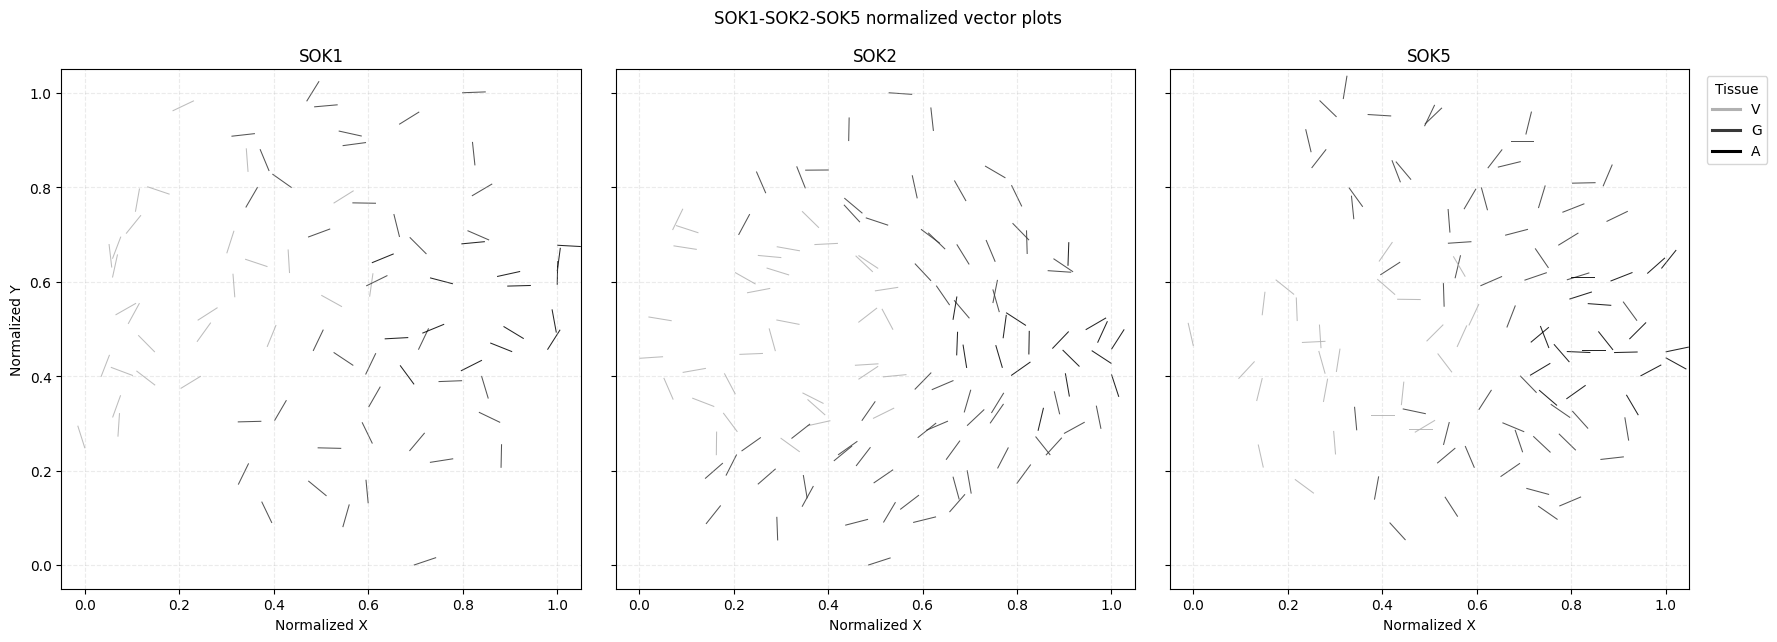

show_only_vag: True
young_emerged_vector_scale: 1.0000004615011935
SOK1 files included:
- polarisation SOK1 timelapse1_pos.csv
- polarisation SOK1 timelapse 2_pos.csv
- polarisation SOK1 timelapse3_pos.csv
- polarisation SOK1 timelapse4_pos.csv
SOK1 total cells plotted: 139
SOK2 files included:
- polarisation t32 SOK2_mirrored.csv
- polarisation t24 SOK2_4_mirrored.csv
- polarisation SOK2 timelapse 2.csv
SOK2 total cells plotted: 162
SOK5 files included:
- polarisation SOK5 timelapse 1_mirrored_pos.csv
- polarisation SOK5 timelapse 2_pos.csv
- polarisation SOK5 timelapse 3_pos.csv
SOK5 total cells plotted: 163


In [431]:
groups = [
    ("SOK1", sok1_csv_files),
    ("SOK2", sok2_csv_files),
    ("SOK5", sok5_csv_files),
]

young_emerged_vector_scale = _stage_vector_scale(groups)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
panel_summaries = []

for ax, (group_name, files) in zip(axes, groups):
    included, n_cells = plot_sok_group(ax, group_name, files, vector_length_scale=young_emerged_vector_scale)
    panel_summaries.append((group_name, included, n_cells))

axes[0].set_ylabel("Normalized Y")
fig.suptitle("SOK1-SOK2-SOK5 normalized vector plots", y=1.02)

legend_items = [("V", tissue_colors["V"]), ("G", tissue_colors["G"]), ("A", tissue_colors["A"])]
if not show_only_vag:
    legend_items.append(("Other", default_color))
for lbl, color in legend_items:
    axes[-1].plot([], [], color=color, linewidth=2.2, label=lbl)
axes[-1].legend(title="Tissue", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
if save_svg:
    svg_path = output_dir / "young_emerged_SOK1_SOK2_SOK5.svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    print("Saved SVG:", svg_path)
plt.show()

print("show_only_vag:", show_only_vag)
print("young_emerged_vector_scale:", young_emerged_vector_scale)
for group_name, included_files, n_cells in panel_summaries:
    print(f"{group_name} files included:")
    for name in included_files:
        print("-", name)
    print(f"{group_name} total cells plotted: {n_cells}")

Saved SVG: /Volumes/Extreme SSD/Work/SOKs/TIFFS_publication/Fig SX_emergence-cellular/polarisation/script/figures/svg/mature_roots_SOK1_SOK2_SOK5.svg


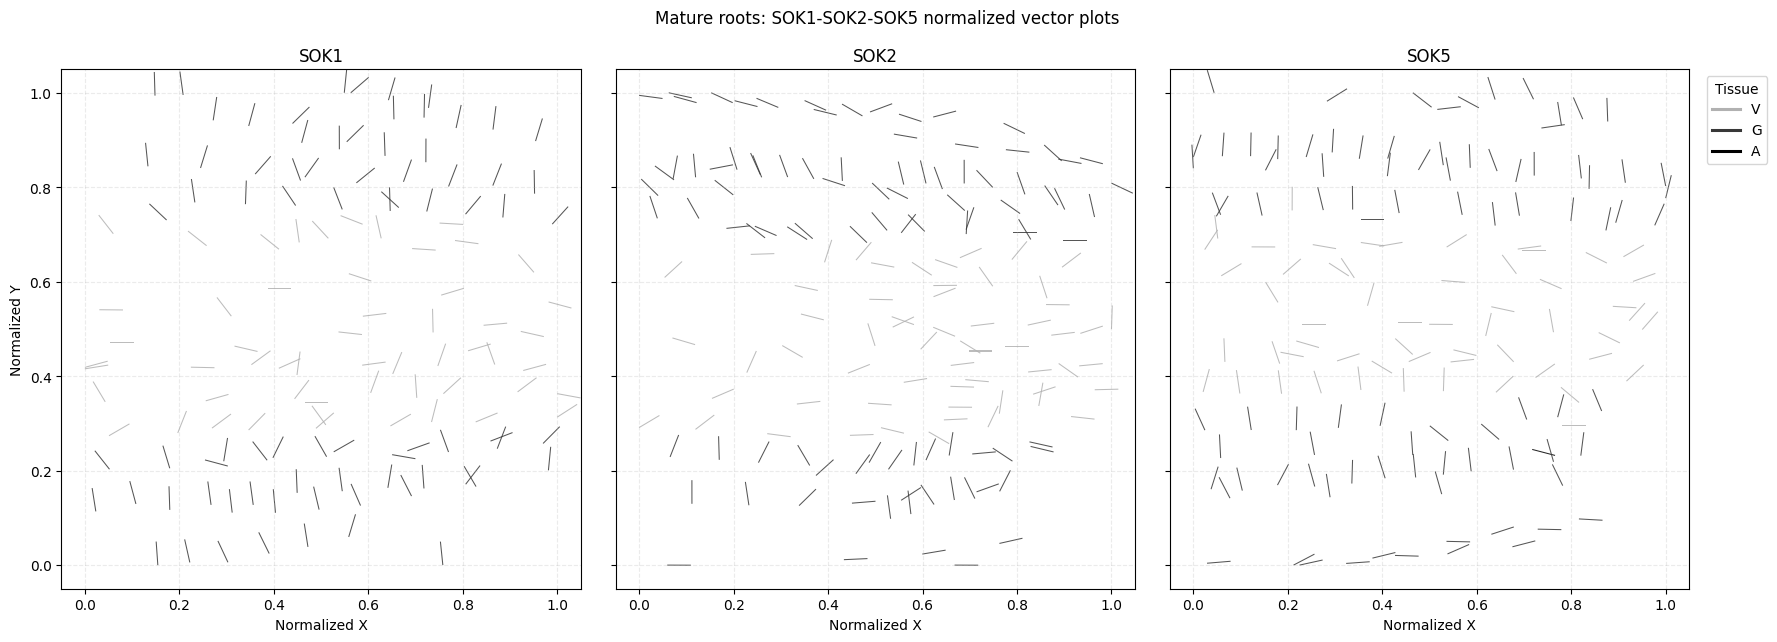

show_only_vag: True
mature_vector_scale: 1.000000466889891
SOK1 mature-roots files included:
- polarisation 2022-06-17_sR659_sR654_check-expression-in-LRP_30p-power.lif - Image002_pos.csv
- polarisation 2021-11-08_sR654-1_stage4-localisation-check.lif - S1_PR_pos.csv
SOK1 mature-roots total cells plotted: 133
SOK2 mature-roots files included:
- polarisation 2021-10-21_sR655-1_selection-for-sR406-cross.lif - S9_PR_pos.csv
- polarisation 2021-08-20_sC193_LRI_polarity_and_F2-selection_Up-is-Apical-PR_Down-is-basal-PR.lif - S10_PR_pos.csv
SOK2 mature-roots total cells plotted: 153
SOK5 mature-roots files included:
- polarisation 2021-10-21_sC194-2_selection-for-sR406-cross-or-propagation.lif - S2_PR_pos.csv
- polarisation C1-2023-09-07_sC194-1-1-4_check-stage3-stage4.lif - S6_RAM_plane2_pos.csv
SOK5 mature-roots total cells plotted: 147


In [432]:
# Mature-roots 3-panel figure (SOK1, SOK2, SOK5)
sok1_mature_csv_files = [
    BASE_DIR / r"SOK1/mature roots/polarisation 2022-06-17_sR659_sR654_check-expression-in-LRP_30p-power.lif - Image002_pos.csv",
    BASE_DIR / r"SOK1/mature roots/polarisation 2021-11-08_sR654-1_stage4-localisation-check.lif - S1_PR_pos.csv",
]

sok2_mature_csv_files = [
    BASE_DIR / r"SOK2/mature roots/polarisation 2021-10-21_sR655-1_selection-for-sR406-cross.lif - S9_PR_pos.csv",
    BASE_DIR / r"SOK2/mature roots/polarisation 2021-08-20_sC193_LRI_polarity_and_F2-selection_Up-is-Apical-PR_Down-is-basal-PR.lif - S10_PR_pos.csv",
]

sok5_mature_csv_files = [
    BASE_DIR / r"SOK5/mature roots/polarisation 2021-10-21_sC194-2_selection-for-sR406-cross-or-propagation.lif - S2_PR_pos.csv",
    BASE_DIR / r"SOK5/mature roots/polarisation C1-2023-09-07_sC194-1-1-4_check-stage3-stage4.lif - S6_RAM_plane2_pos.csv",
]

mature_groups = [
    ("SOK1", sok1_mature_csv_files),
    ("SOK2", sok2_mature_csv_files),
    ("SOK5", sok5_mature_csv_files),
]

mature_vector_scale = _stage_vector_scale(mature_groups)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
mature_panel_summaries = []

for ax, (group_name, files) in zip(axes, mature_groups):
    included, n_cells = plot_sok_group(ax, group_name, files, vector_length_scale=mature_vector_scale)
    mature_panel_summaries.append((group_name, included, n_cells))

axes[0].set_ylabel("Normalized Y")
fig.suptitle("Mature roots: SOK1-SOK2-SOK5 normalized vector plots", y=1.02)

legend_items = [("V", tissue_colors["V"]), ("G", tissue_colors["G"]), ("A", tissue_colors["A"])]
if not show_only_vag:
    legend_items.append(("Other", default_color))
for lbl, color in legend_items:
    axes[-1].plot([], [], color=color, linewidth=2.2, label=lbl)
axes[-1].legend(title="Tissue", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
if save_svg:
    svg_path = output_dir / "mature_roots_SOK1_SOK2_SOK5.svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    print("Saved SVG:", svg_path)
plt.show()

print("show_only_vag:", show_only_vag)
print("mature_vector_scale:", mature_vector_scale)
for group_name, included_files, n_cells in mature_panel_summaries:
    print(f"{group_name} mature-roots files included:")
    for name in included_files:
        print("-", name)
    print(f"{group_name} mature-roots total cells plotted: {n_cells}")

Saved SVG: /Volumes/Extreme SSD/Work/SOKs/TIFFS_publication/Fig SX_emergence-cellular/polarisation/script/figures/svg/stage2_SOK1_SOK2_SOK5.svg


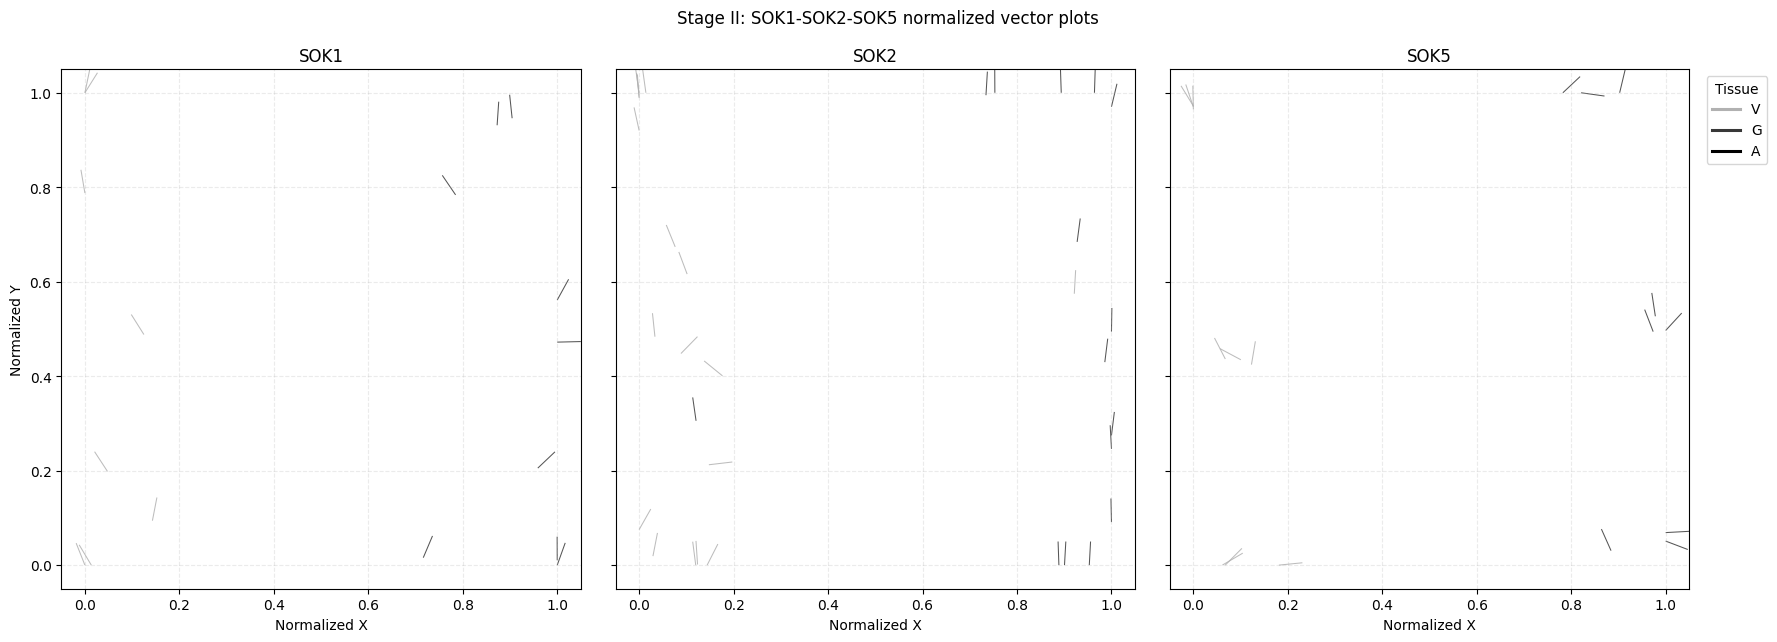

show_only_vag: True
stage2_vector_scale: 1.0000004486163994
SOK1 stage-II files included:
- polarisation  C1-2021-11-08_sR654-1_stage4-localisation-check.lif - S2_LR4_stage2.csv
- polarisation C1-2021-10-22_sR658-2_check-for-stage4-SOK1-localization.lif - sR658-2_S3_LR2_stage2.csv
- polarisation C1-MAX_2021-11-09_sR654-1_stage4-localisation-check-2.lif - S1_LR2_zStack.csv
- polarisation C1-2021-11-08_sR654-1_stage4-localisation-check.lif - S8_LR1_stage4.csv
SOK1 stage-II total cells plotted: 21
SOK2 stage-II files included:
- polarisation C1-2022-11-11_sC193-1-1-2_SOK2-localisation-in-young-pericycle-cells.lif - S1_stage2.csv
- polarisation C1-2021-06-29_pRPS5A-SOK2-YFP_propagated-seeds-check-for-YFP.lif - plant2_LR-1_st2.csv
- polarisation C1-2021-06-29_pRPS5A-SOK2-YFP_propagated-seeds-check-for-YFP.lif - plant2_LR-2.csv
- polarisation C1-2021-08-20_sC193_LRI_polarity_and_F2-selection_Up-is-Apical-PR_Down-is-basal-PR.lif - S6_LR2_stage2.csv
- polarisation C1-2021-08-20_sC193_LRI_polar

In [433]:
# Stage II 3-panel figure (SOK1, SOK2, SOK5)
sok1_stage2_csv_files = [
    BASE_DIR / r"SOK1/young LRP/polarisation  C1-2021-11-08_sR654-1_stage4-localisation-check.lif - S2_LR4_stage2.csv",
    BASE_DIR / r"SOK1/young LRP/polarisation C1-2021-10-22_sR658-2_check-for-stage4-SOK1-localization.lif - sR658-2_S3_LR2_stage2.csv",
    BASE_DIR / r"SOK1/young LRP/polarisation C1-MAX_2021-11-09_sR654-1_stage4-localisation-check-2.lif - S1_LR2_zStack.csv",
    BASE_DIR / r"SOK1/young LRP/polarisation C1-2021-11-08_sR654-1_stage4-localisation-check.lif - S8_LR1_stage4.csv",
]

sok2_stage2_csv_files = [
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2022-11-11_sC193-1-1-2_SOK2-localisation-in-young-pericycle-cells.lif - S1_stage2.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2021-06-29_pRPS5A-SOK2-YFP_propagated-seeds-check-for-YFP.lif - plant2_LR-1_st2.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2021-06-29_pRPS5A-SOK2-YFP_propagated-seeds-check-for-YFP.lif - plant2_LR-2.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2021-08-20_sC193_LRI_polarity_and_F2-selection_Up-is-Apical-PR_Down-is-basal-PR.lif - S6_LR2_stage2.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2021-08-20_sC193_LRI_polarity_and_F2-selection_Up-is-Apical-PR_Down-is-basal-PR.lif - S10_LR1_Stage2.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2022-06-16_sC193-1-2-1_selection-for-scr-cross_and_polarisation-in-vasculature.lif - S1_stage2.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2022-06-16_sC193-1-2-1_selection-for-scr-cross_and_polarisation-in-vasculature.lif - S2_stage2.csv",
]

# SOK5 stage II files inferred from available stage2 entries in SOK5/young LRP
sok5_stage2_csv_files = [
    BASE_DIR / r"SOK5/young LRP/polarisation C1-2021-10-21_sC194-2_selection-for-sR406-cross-or-propagation.lif - S6_LR2_stage2_NICE.csv",
    BASE_DIR / r"SOK5/young LRP/polarisation C1-2022-06-30_sC194-1-1_checkPolarityInInnerStage2CellsIOWFutureVascularCells.lif - S1_LRP2_stage2.csv",
    BASE_DIR / r"SOK5/young LRP/polarisation 2022-06-30_sC194-1-1_checkPolarityInInnerStage2CellsIOWFutureVascularCells.lif - S3_LRP2_stage2_zStack-1.csv",
]

stage2_groups = [
    ("SOK1", sok1_stage2_csv_files),
    ("SOK2", sok2_stage2_csv_files),
    ("SOK5", sok5_stage2_csv_files),
]

stage2_vector_scale = _stage_vector_scale(stage2_groups)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
stage2_panel_summaries = []

for ax, (group_name, files) in zip(axes, stage2_groups):
    included, n_cells = plot_sok_group(ax, group_name, files, vector_length_scale=stage2_vector_scale)
    stage2_panel_summaries.append((group_name, included, n_cells))

axes[0].set_ylabel("Normalized Y")
fig.suptitle("Stage II: SOK1-SOK2-SOK5 normalized vector plots", y=1.02)

legend_items = [("V", tissue_colors["V"]), ("G", tissue_colors["G"]), ("A", tissue_colors["A"])]
if not show_only_vag:
    legend_items.append(("Other", default_color))
for lbl, color in legend_items:
    axes[-1].plot([], [], color=color, linewidth=2.2, label=lbl)
axes[-1].legend(title="Tissue", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
if save_svg:
    svg_path = output_dir / "stage2_SOK1_SOK2_SOK5.svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    print("Saved SVG:", svg_path)
plt.show()

print("show_only_vag:", show_only_vag)
print("stage2_vector_scale:", stage2_vector_scale)
for group_name, included_files, n_cells in stage2_panel_summaries:
    print(f"{group_name} stage-II files included:")
    for name in included_files:
        print("-", name)
    print(f"{group_name} stage-II total cells plotted: {n_cells}")

Saved SVG: /Volumes/Extreme SSD/Work/SOKs/TIFFS_publication/Fig SX_emergence-cellular/polarisation/script/figures/svg/stage4_SOK1_SOK2_SOK5.svg


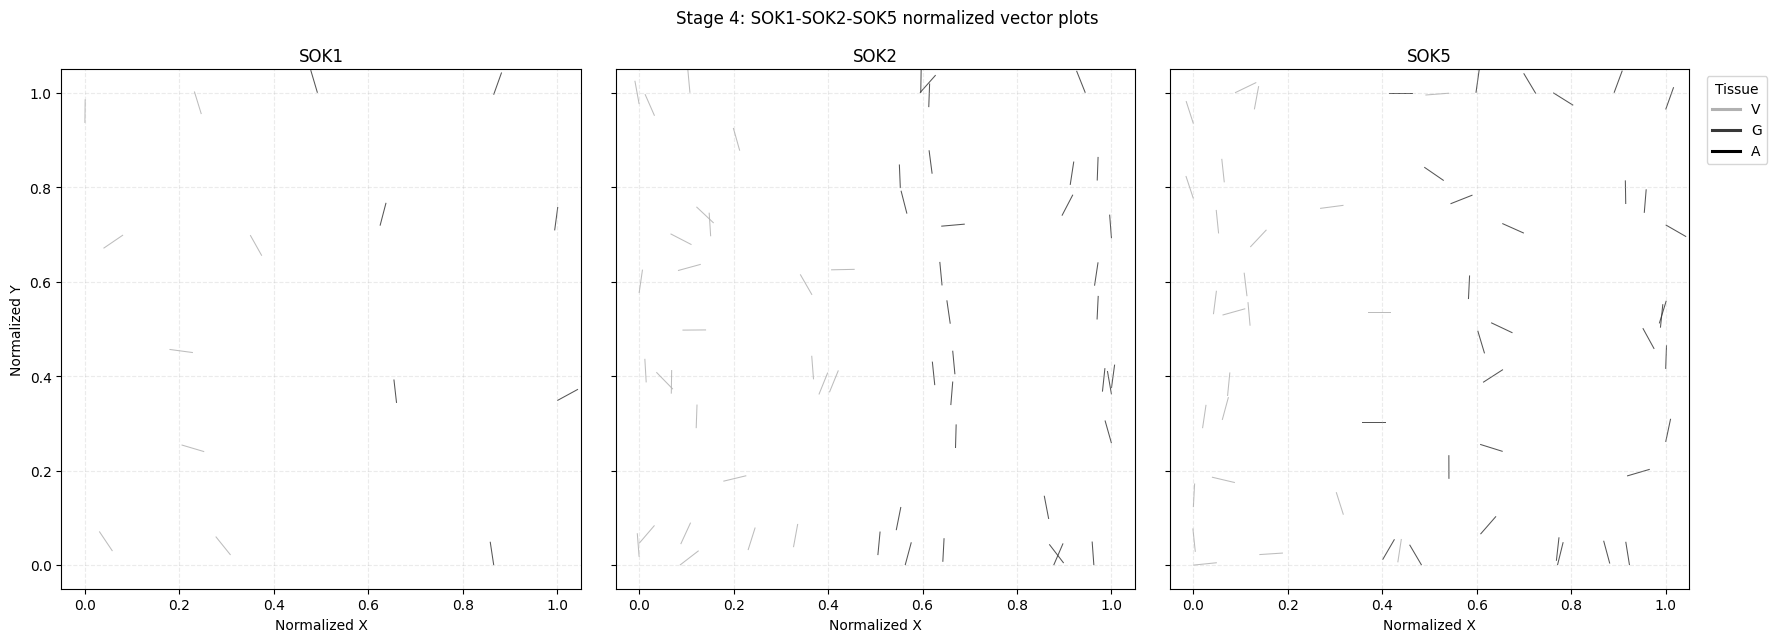

show_only_vag: True
stage4_vector_scale: 1.0000004515180692
SOK1 stage-4 files included:
- polarisation C1-st4_2022-06-09_sC192-1-2-3_check_polarity-in-vasculature.lif - S1_stage4_8xAvg_8xAccu.csv
SOK1 stage-4 total cells plotted: 16
SOK2 stage-4 files included:
- polarisation C1-2023-09-06_sC193-1-2-1_check-stage3-stage4.lif - S2_LR3_stage3_NICE.csv
- polarisation C1-2024-07-04_sC193-1-2-1-6_stage3-4-5_polarization_SOK2.lif - S5_LRP1_stage4_perfect_frameAccu2x.csv
- polarisation C1-2024-07-04_sC193-1-2-1-6_stage3-4-5_polarization_SOK2.lif - S5_LRP2_stage4_perfect_frameAccu2x.csv
- polarisation C1-t9_2021-07-27_15.03.38_pRPS5A-SOK2-YFP_x_pUBQ10-LTi6B-mCherry(x2)_stack_dc-drop_track2_track3_SINGLESLICE-1.csv
SOK2 stage-4 total cells plotted: 58
SOK5 stage-4 files included:
- polarisation C1-2021-09-09_sR633-2_propagation-selection_and-live-imaging.lif - sR633-2_S1_LRP-3_stage4.csv
- polarisation C1-2022-06-30_sC194-1-1_checkPolarityInInnerStage2CellsIOWFutureVascularCells.lif - S5_LRP1_

In [434]:
# Stage 4 3-panel figure (SOK1, SOK2, SOK5)
sok1_stage4_csv_files = [
    BASE_DIR / r"SOK1/young LRP/polarisation C1-st4_2022-06-09_sC192-1-2-3_check_polarity-in-vasculature.lif - S1_stage4_8xAvg_8xAccu.csv",
]

sok2_stage4_csv_files = [
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2023-09-06_sC193-1-2-1_check-stage3-stage4.lif - S2_LR3_stage3_NICE.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2024-07-04_sC193-1-2-1-6_stage3-4-5_polarization_SOK2.lif - S5_LRP1_stage4_perfect_frameAccu2x.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-2024-07-04_sC193-1-2-1-6_stage3-4-5_polarization_SOK2.lif - S5_LRP2_stage4_perfect_frameAccu2x.csv",
    BASE_DIR / r"SOK2/young LRP/polarisation C1-t9_2021-07-27_15.03.38_pRPS5A-SOK2-YFP_x_pUBQ10-LTi6B-mCherry(x2)_stack_dc-drop_track2_track3_SINGLESLICE-1.csv",
]

sok5_stage4_csv_files = [
    BASE_DIR / r"SOK5/young LRP/polarisation C1-2021-09-09_sR633-2_propagation-selection_and-live-imaging.lif - sR633-2_S1_LRP-3_stage4.csv",
    BASE_DIR / r"SOK5/young LRP/polarisation C1-2022-06-30_sC194-1-1_checkPolarityInInnerStage2CellsIOWFutureVascularCells.lif - S5_LRP1_stage3_zSlice1.csv",
    BASE_DIR / r"SOK5/young LRP/polarisation C1-2023-09-07_sC194-1-1-4_check-stage3-stage4.lif - S8_LR2_stage3_plane1.csv",
    BASE_DIR / r"SOK5/young LRP/polarisation z1_t41_2021-05-19_retrack-on-2025-02-28_zStack_nice-1.csv",
]

stage4_groups = [
    ("SOK1", sok1_stage4_csv_files),
    ("SOK2", sok2_stage4_csv_files),
    ("SOK5", sok5_stage4_csv_files),
]

stage4_vector_scale = _stage_vector_scale(stage4_groups)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
stage4_panel_summaries = []

for ax, (group_name, files) in zip(axes, stage4_groups):
    included, n_cells = plot_sok_group(ax, group_name, files, vector_length_scale=stage4_vector_scale)
    stage4_panel_summaries.append((group_name, included, n_cells))

axes[0].set_ylabel("Normalized Y")
fig.suptitle("Stage 4: SOK1-SOK2-SOK5 normalized vector plots", y=1.02)

legend_items = [("V", tissue_colors["V"]), ("G", tissue_colors["G"]), ("A", tissue_colors["A"])]
if not show_only_vag:
    legend_items.append(("Other", default_color))
for lbl, color in legend_items:
    axes[-1].plot([], [], color=color, linewidth=2.2, label=lbl)
axes[-1].legend(title="Tissue", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
if save_svg:
    svg_path = output_dir / "stage4_SOK1_SOK2_SOK5.svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    print("Saved SVG:", svg_path)
plt.show()

print("show_only_vag:", show_only_vag)
print("stage4_vector_scale:", stage4_vector_scale)
for group_name, included_files, n_cells in stage4_panel_summaries:
    print(f"{group_name} stage-4 files included:")
    for name in included_files:
        print("-", name)
    print(f"{group_name} stage-4 total cells plotted: {n_cells}")

Saved SVG: /Volumes/Extreme SSD/Work/SOKs/TIFFS_publication/Fig SX_emergence-cellular/polarisation/script/figures/svg/all_stages_grid_SOK1_SOK2_SOK5_MT_corrected.svg


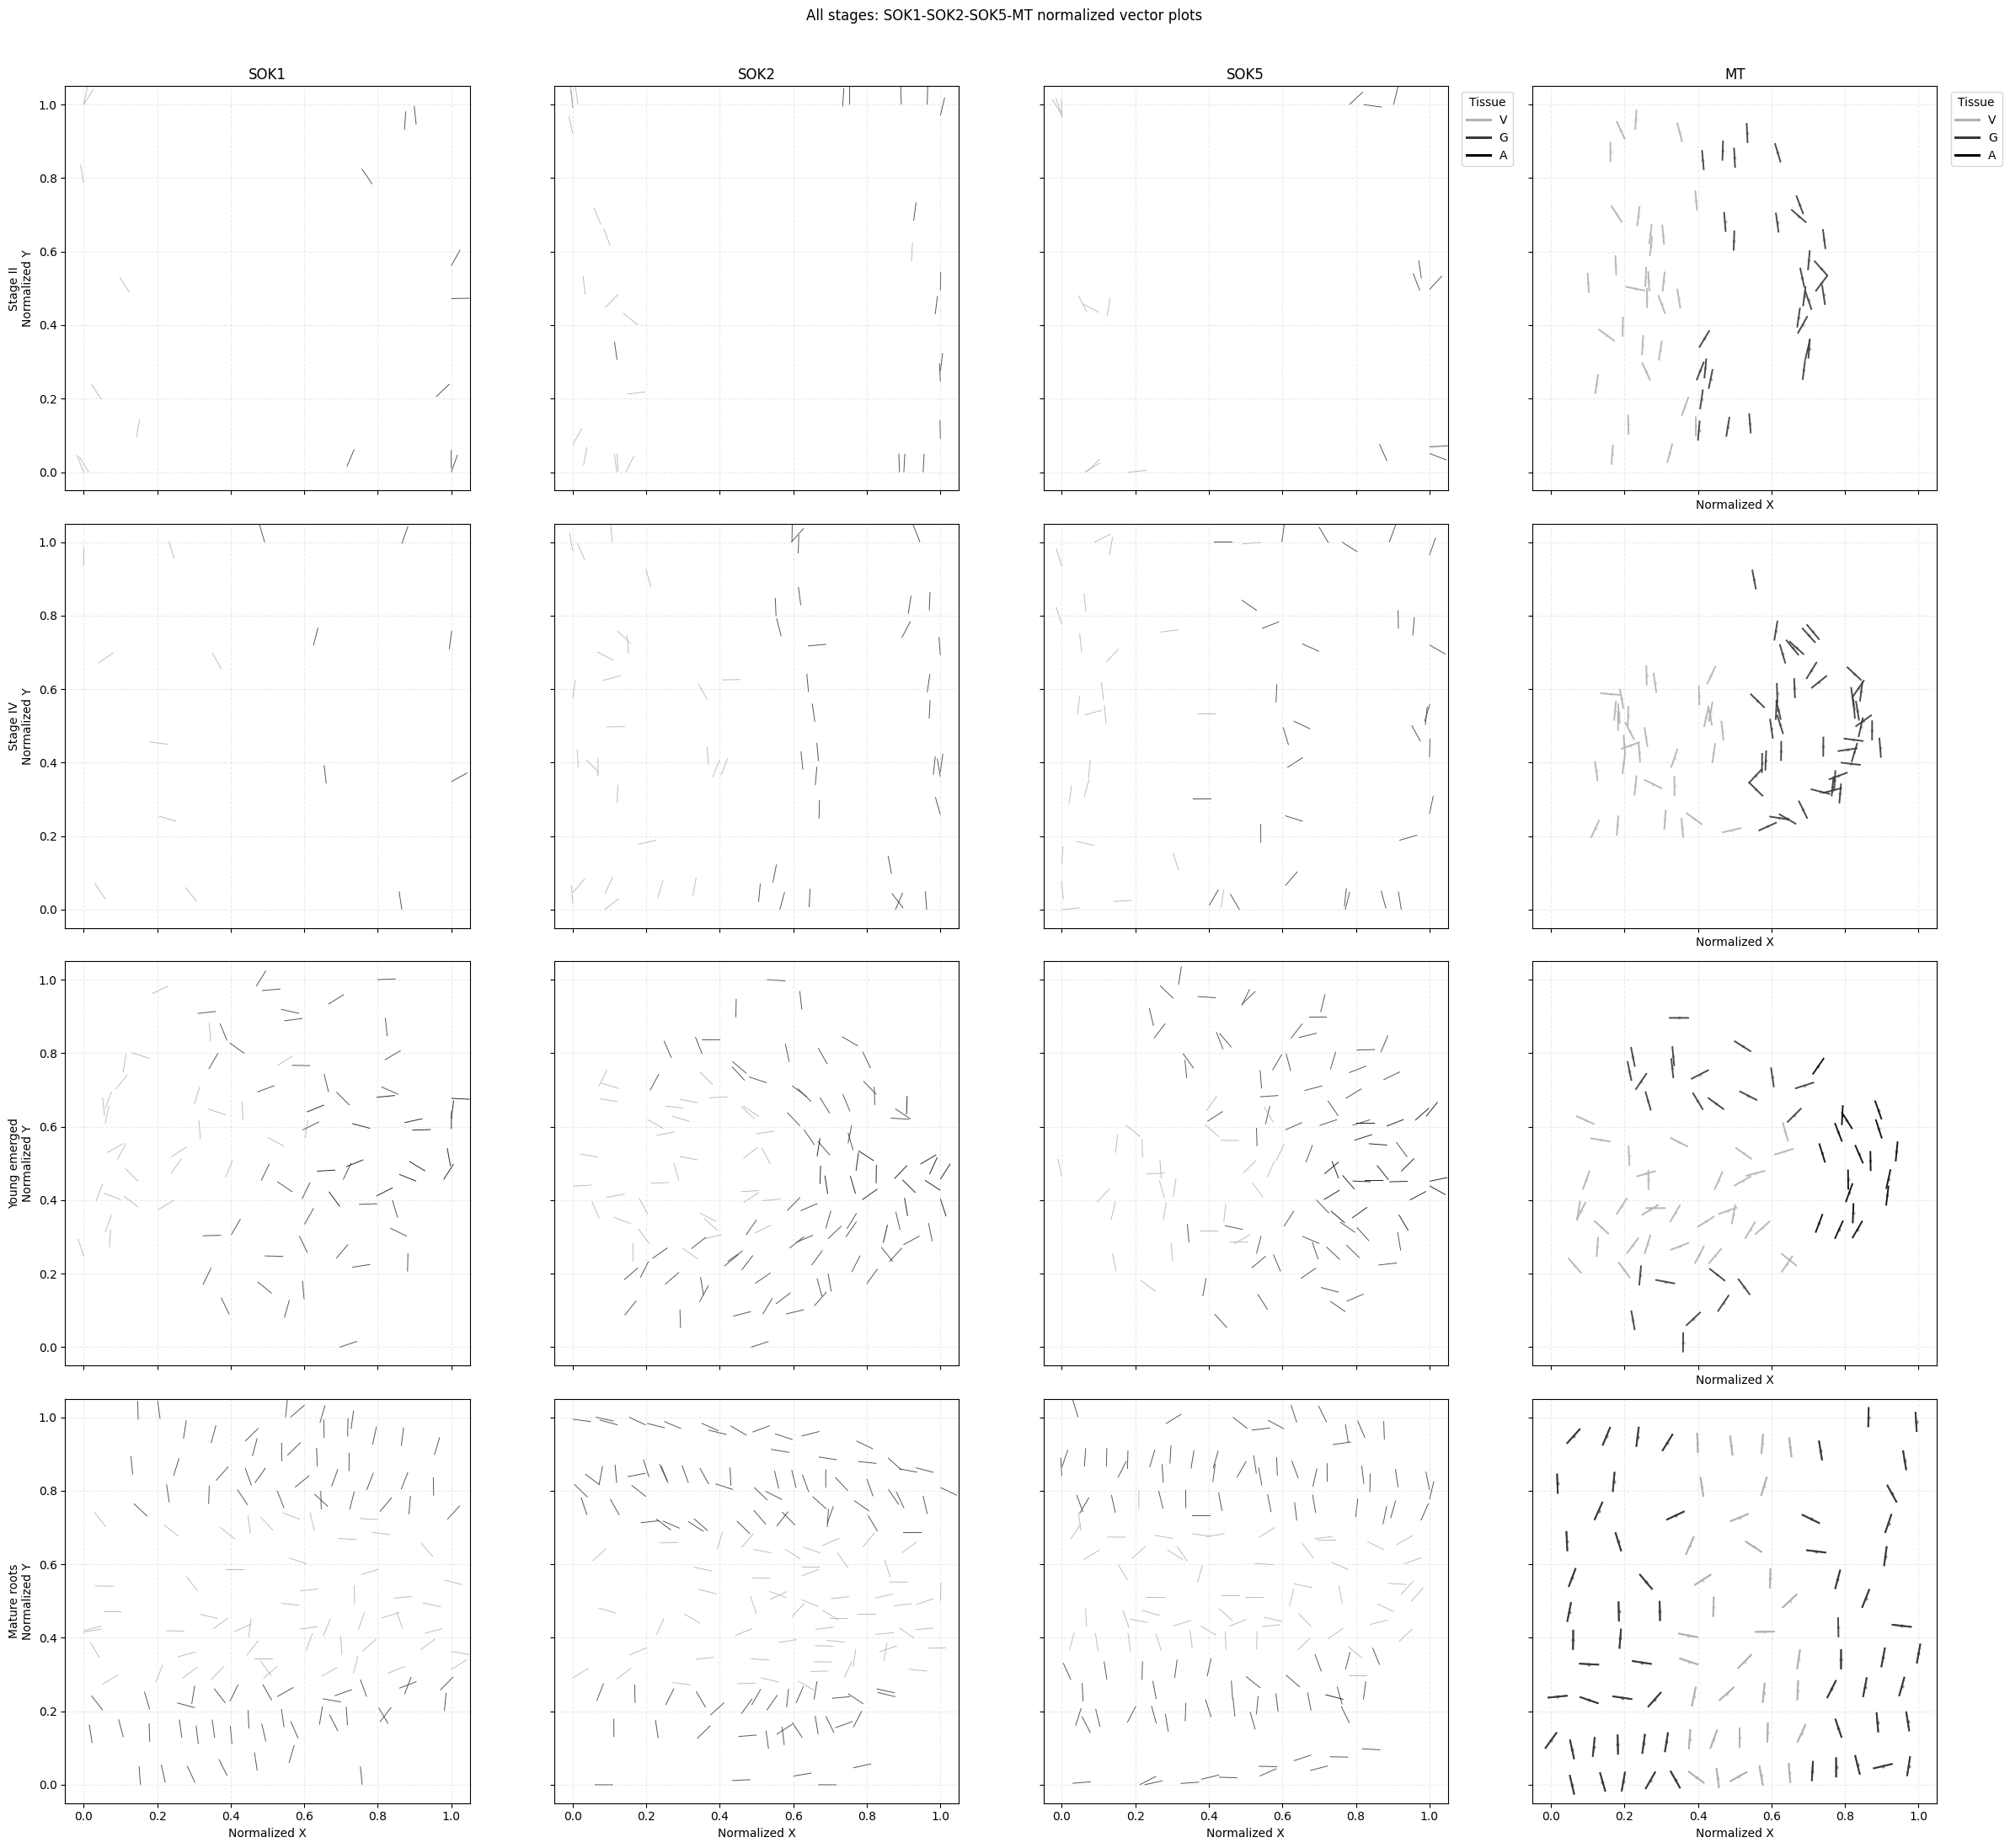

show_only_vag: True
use_mt_intensity_correction: False
use_mt_anisotropy_length_scaling: False
MT anisotropy column used: anisotropy
stage_vector_scales: {'Stage II': 1.0000004486163994, 'Stage IV': 1.0000004515180692, 'Young emerged': 1.0000004615011935, 'Mature roots': 1.000000466889891}
Stage II | SOK1 files included:
- polarisation  C1-2021-11-08_sR654-1_stage4-localisation-check.lif - S2_LR4_stage2.csv
- polarisation C1-2021-10-22_sR658-2_check-for-stage4-SOK1-localization.lif - sR658-2_S3_LR2_stage2.csv
- polarisation C1-MAX_2021-11-09_sR654-1_stage4-localisation-check-2.lif - S1_LR2_zStack.csv
- polarisation C1-2021-11-08_sR654-1_stage4-localisation-check.lif - S8_LR1_stage4.csv
Stage II | SOK1 total cells plotted: 21
Stage II | SOK2 files included:
- polarisation C1-2022-11-11_sC193-1-1-2_SOK2-localisation-in-young-pericycle-cells.lif - S1_stage2.csv
- polarisation C1-2021-06-29_pRPS5A-SOK2-YFP_propagated-seeds-check-for-YFP.lif - plant2_LR-1_st2.csv
- polarisation C1-2021-06-2

In [435]:
# Combined 4-stage grid: columns = SOK1/SOK2/SOK5/MT, rows = stage II/stage IV/young emerged/mature roots

all_stage_rows = [

    ("Stage II", [("SOK1", sok1_stage2_csv_files), ("SOK2", sok2_stage2_csv_files), ("SOK5", sok5_stage2_csv_files)]),

    ("Stage IV", [("SOK1", sok1_stage4_csv_files), ("SOK2", sok2_stage4_csv_files), ("SOK5", sok5_stage4_csv_files)]),

    ("Young emerged", [("SOK1", sok1_csv_files), ("SOK2", sok2_csv_files), ("SOK5", sok5_csv_files)]),

    ("Mature roots", [("SOK1", sok1_mature_csv_files), ("SOK2", sok2_mature_csv_files), ("SOK5", sok5_mature_csv_files)]),

]



# MT source tables and row-to-stage mapping.

# "Young emerged" uses stage 6 as requested: Stage VI (young emerged).

mt_excel_path = BASE_DIR / "MT" / "data_redone_after_reordering_and_verification_layers.xlsx"

mt_pr_ods_path = BASE_DIR / "MT" / "MT-PR.ods"

mt_stage_map = {

    "Stage II": [2],

    "Stage IV": [4],

    "Young emerged": [6],

}





# Panel-level vector organization metric (nematic order):

# 0 = disorganized orientations, 1 = perfectly aligned orientations.

def _nematic_order_from_angles(theta_rad):

    theta = np.asarray(theta_rad, dtype=float)

    if theta.size == 0:

        return np.nan

    c2 = np.cos(2.0 * theta)

    s2 = np.sin(2.0 * theta)

    return float(np.sqrt(c2.mean() ** 2 + s2.mean() ** 2))





def _sok_panel_nematic_order(file_list):

    ux, uy = vector_cols

    all_theta = []



    for csv_path in file_list:

        csv_path = Path(csv_path)

        if not csv_path.exists():

            continue



        df = pd.read_csv(csv_path)

        required = [ux, uy]

        if not set(required).issubset(df.columns):

            continue



        vec_df = df.dropna(subset=required).copy()

        if vec_df.empty:

            continue



        if show_only_vag and "Tissue" in vec_df.columns:

            tissue = vec_df["Tissue"].fillna("").astype(str).str.strip()

            vec_df = vec_df[tissue.isin(tissue_colors.keys())]

            if vec_df.empty:

                continue



        u = pd.to_numeric(vec_df[ux], errors="coerce")

        v = pd.to_numeric(vec_df[uy], errors="coerce")

        valid = u.notna() & v.notna()

        if not valid.any():

            continue



        u = u[valid].to_numpy()

        v = v[valid].to_numpy()

        mags = np.hypot(u, v)

        nonzero = mags > 0

        if not np.any(nonzero):

            continue



        all_theta.append(np.arctan2(v[nonzero], u[nonzero]))



    if not all_theta:

        return np.nan, 0



    theta = np.concatenate(all_theta)

    return _nematic_order_from_angles(theta), int(theta.size)





def _mt_panel_nematic_order_from_stage(mt_df, stage_values, angle_col="average fibril orientation"):

    if mt_df is None:

        return np.nan, 0



    subset = mt_df[mt_df["stage"].isin(stage_values)].copy()

    if angle_col not in subset.columns:

        return np.nan, 0



    angles_deg = pd.to_numeric(subset[angle_col], errors="coerce").dropna()

    if angles_deg.empty:

        return np.nan, 0



    theta = np.deg2rad(angles_deg.to_numpy())

    return _nematic_order_from_angles(theta), int(theta.size)





def _mt_panel_nematic_order_from_pr(mt_pr_df, angle_col="average fibril orientation", rotate_deg=-90):

    if mt_pr_df is None or angle_col not in mt_pr_df.columns:

        return np.nan, 0



    angles_deg = pd.to_numeric(mt_pr_df[angle_col], errors="coerce").dropna()

    if angles_deg.empty:

        return np.nan, 0



    theta = np.deg2rad(angles_deg.to_numpy() + rotate_deg)

    return _nematic_order_from_angles(theta), int(theta.size)





mt_df = None

mt_anisotropy_col = mt_raw_anisotropy_col

if mt_excel_path.exists():

    mt_df = pd.read_excel(mt_excel_path)

    if "stage" not in mt_df.columns:

        print(f"MT file missing 'stage' column: {mt_excel_path}")

        mt_df = None

    else:

        mt_anisotropy_col = select_mt_anisotropy_column(mt_df)

else:

    print(f"MT file not found: {mt_excel_path}")



mt_pr_df = None

if mt_pr_ods_path.exists():

    mt_pr_df = load_mt_pr_ods_relative(mt_pr_ods_path)

else:

    print(f"Mature-roots MT file not found: {mt_pr_ods_path}")



fig, axes = plt.subplots(4, 4, figsize=(24, 22), sharex=True, sharey=True)

all_stage_summaries = []

mt_stage_summaries = []

stage_vector_scales = {}

stage_cell_totals = {}

panel_organization = []



for row_idx, (stage_name, stage_groups) in enumerate(all_stage_rows):

    stage_vector_scale = _stage_vector_scale(stage_groups)

    stage_vector_scales[stage_name] = stage_vector_scale

    stage_cell_totals[stage_name] = 0



    for col_idx, (group_name, files) in enumerate(stage_groups):

        ax = axes[row_idx, col_idx]

        included, n_cells = plot_sok_group(

            ax,

            group_name,

            files,

            vector_length_scale=stage_vector_scale,

        )

        all_stage_summaries.append((stage_name, group_name, included, n_cells))

        stage_cell_totals[stage_name] += n_cells



        org_score, n_vec = _sok_panel_nematic_order(files)

        panel_organization.append((stage_name, group_name, "SOK", org_score, n_vec))



        if row_idx == 0:

            ax.set_title(group_name)

        else:

            ax.set_title("")



        if row_idx < len(all_stage_rows) - 1:

            ax.set_xlabel("")



        if col_idx == 0:

            ax.set_ylabel(f"{stage_name}\nNormalized Y")

        else:

            ax.set_ylabel("")



    mt_ax = axes[row_idx, 3]

    mt_ax.set_ylabel("")

    mt_ax.set_title("MT" if row_idx == 0 else "")



    if stage_name == "Mature roots":

        if mt_pr_df is not None:

            n_lines = plot_mt_vectors(mt_ax, mt_pr_df, rotate_deg=-90, rotate_space_deg=90, mirror_space_x=True)

            mt_stage_summaries.append((stage_name, ["MT-PR"], n_lines))

            org_score, n_vec = _mt_panel_nematic_order_from_pr(mt_pr_df, rotate_deg=-90)

            panel_organization.append((stage_name, "MT", "MT", org_score, n_vec))

        else:

            mt_ax.set_xlim(-0.05, 1.05)

            mt_ax.set_ylim(-0.05, 1.05)

            mt_ax.set_aspect("equal", adjustable="box")

            mt_ax.grid(True, linestyle="--", alpha=0.25)

            mt_ax.set_xlabel("Normalized X")

            mt_ax.text(0.5, 0.5, "MT-PR unavailable", ha="center", va="center")

            mt_stage_summaries.append((stage_name, ["MT-PR"], 0))

            panel_organization.append((stage_name, "MT", "MT", np.nan, 0))

        continue



    stage_values = mt_stage_map.get(stage_name)

    if mt_df is not None and stage_values:

        n_lines = plot_mt_stage(

            mt_ax,

            mt_df,

            stage_values,

            stage_name,

            anisotropy_col=mt_anisotropy_col,

        )

        mt_stage_summaries.append((stage_name, stage_values, n_lines))

        org_score, n_vec = _mt_panel_nematic_order_from_stage(mt_df, stage_values)

        panel_organization.append((stage_name, "MT", "MT", org_score, n_vec))

    else:

        mt_ax.set_xlim(-0.05, 1.05)

        mt_ax.set_ylim(-0.05, 1.05)

        mt_ax.set_aspect("equal", adjustable="box")

        mt_ax.grid(True, linestyle="--", alpha=0.25)

        mt_ax.set_xlabel("" if row_idx < len(all_stage_rows) - 1 else "Normalized X")

        if stage_values:

            mt_ax.text(0.5, 0.5, "MT data unavailable", ha="center", va="center")

            mt_stage_summaries.append((stage_name, stage_values, 0))

            panel_organization.append((stage_name, "MT", "MT", np.nan, 0))

        else:

            mt_ax.text(0.5, 0.5, "N/A", ha="center", va="center")

            mt_stage_summaries.append((stage_name, [], 0))

            panel_organization.append((stage_name, "MT", "MT", np.nan, 0))



legend_items = [("V", tissue_colors["V"]), ("G", tissue_colors["G"]), ("A", tissue_colors["A"])]

if not show_only_vag:

    legend_items.append(("Other", default_color))

for lbl, color in legend_items:

    axes[0, 2].plot([], [], color=color, linewidth=2.2, label=lbl)

axes[0, 2].legend(title="Tissue", bbox_to_anchor=(1.02, 1), loc="upper left")



for lbl, color in legend_items:

    axes[0, 3].plot([], [], color=color, linewidth=2.2, label=lbl)

axes[0, 3].legend(title="Tissue", bbox_to_anchor=(1.02, 1), loc="upper left")



fig.suptitle("All stages: SOK1-SOK2-SOK5-MT normalized vector plots", y=0.995)

plt.tight_layout(rect=[0, 0, 1, 0.985])



if save_svg:

    svg_path = output_dir / "all_stages_grid_SOK1_SOK2_SOK5_MT_corrected.svg"

    fig.savefig(svg_path, format="svg", bbox_inches="tight")

    print("Saved SVG:", svg_path)

plt.show()



print("show_only_vag:", show_only_vag)

print("use_mt_intensity_correction:", use_mt_intensity_correction)

print("use_mt_anisotropy_length_scaling:", use_mt_anisotropy_length_scaling)

print("MT anisotropy column used:", mt_anisotropy_col)

print("stage_vector_scales:", stage_vector_scales)

for stage_name, group_name, included_files, n_cells in all_stage_summaries:

    print(f"{stage_name} | {group_name} files included:")

    for name in included_files:

        print("-", name)

    print(f"{stage_name} | {group_name} total cells plotted: {n_cells}")



print("Stage totals (SOK1+SOK2+SOK5):")

for stage_name, n_cells in stage_cell_totals.items():

    print(f"{stage_name}: {n_cells}")



print("MT summaries:")

for stage_name, stage_values, n_lines in mt_stage_summaries:

    print(f"{stage_name} | source={stage_values} | plotted lines={n_lines}")



print("\nPanel organization (nematic order, 0-1):")

for stage_name, panel_name, panel_type, score, n_vec in panel_organization:

    score_text = f"{score:.3f}" if pd.notna(score) else "nan"

    print(f"{stage_name:13s} | {panel_name:4s} | {panel_type:3s} | score={score_text} | n_vectors={n_vec}")

Saved SVG: /Volumes/Extreme SSD/Work/SOKs/TIFFS_publication/Fig SX_emergence-cellular/polarisation/script/figures/svg/organisation_vs_stage_lines.svg


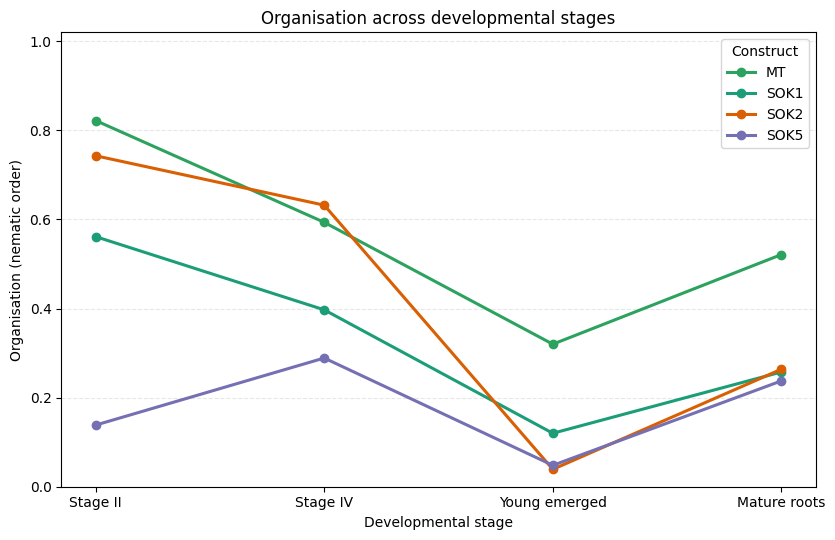


Organisation table used for statistics:
        stage construct  organization  n_vectors
     Stage II        MT      0.822060         61
     Stage IV        MT      0.593558        119
Young emerged        MT      0.319976         89
 Mature roots        MT      0.521209        185
     Stage II      SOK1      0.561440         17
     Stage IV      SOK1      0.397096         15
Young emerged      SOK1      0.119984         83
 Mature roots      SOK1      0.257626        133
     Stage II      SOK2      0.742967         46
     Stage IV      SOK2      0.632042         58
Young emerged      SOK2      0.039060        117
 Mature roots      SOK2      0.263803        153
     Stage II      SOK5      0.138330         18
     Stage IV      SOK5      0.288872         56
Young emerged      SOK5      0.048019        104
 Mature roots      SOK5      0.237635        155

One-way ANOVA across constructs: F=2.1225, p=0.1507

Tukey HSD (construct pairwise):
Multiple Comparison of Means - Tukey HSD

In [436]:
# Organisation-vs-stage plot + ANOVA + Tukey
from scipy import stats

stage_order = ["Stage II", "Stage IV", "Young emerged", "Mature roots"]

org_df = pd.DataFrame(
    panel_organization,
    columns=["stage", "panel", "panel_type", "organization", "n_vectors"],
)
org_df = org_df.rename(columns={"panel": "construct"})
org_df = org_df[org_df["organization"].notna()].copy()
org_df["stage"] = pd.Categorical(org_df["stage"], categories=stage_order, ordered=True)
org_df = org_df.sort_values(["construct", "stage"])

plot_df = org_df[org_df["construct"].isin(["SOK1", "SOK2", "SOK5", "MT"])].copy()

construct_colors = {
    "SOK1": "#1b9e77",
    "SOK2": "#d95f02",
    "SOK5": "#7570b3",
    "MT": "#2ca25f",
}

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for construct, g in plot_df.groupby("construct", sort=False):
    g = g.sort_values("stage")
    ax.plot(
        g["stage"].astype(str),
        g["organization"],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=construct,
        color=construct_colors.get(construct, None),
    )

ax.set_xlabel("Developmental stage")
ax.set_ylabel("Organisation (nematic order)")
ax.set_ylim(0, 1.02)
ax.set_title("Organisation across developmental stages")
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
ax.legend(title="Construct")
plt.tight_layout()
if save_svg:
    svg_path = output_dir / "organisation_vs_stage_lines.svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    print("Saved SVG:", svg_path)
plt.show()

print("\nOrganisation table used for statistics:")
print(plot_df[["stage", "construct", "organization", "n_vectors"]].to_string(index=False))

# One-way ANOVA by construct (using stages as repeated observations per construct)
anova_df = plot_df[["construct", "organization"]].dropna()
groups = [
    g["organization"].to_numpy()
    for _, g in anova_df.groupby("construct")
    if len(g) >= 2
]

if len(groups) >= 2:
    f_stat, p_val = stats.f_oneway(*groups)
    print(f"\nOne-way ANOVA across constructs: F={f_stat:.4f}, p={p_val:.4g}")
else:
    print("\nNot enough data for ANOVA across constructs.")

# Tukey HSD pairwise comparison between constructs
try:
    from statsmodels.stats.multicomp import pairwise_tukeyhsd

    if anova_df["construct"].nunique() >= 2 and len(anova_df) >= 4:
        tukey = pairwise_tukeyhsd(
            endog=anova_df["organization"],
            groups=anova_df["construct"],
            alpha=0.05,
        )
        print("\nTukey HSD (construct pairwise):")
        print(tukey)
    else:
        print("\nNot enough data for Tukey HSD.")
except Exception as exc:
    print("\nTukey HSD skipped (statsmodels unavailable or failed):", exc)

# Optional: stage-wise ANOVA (only if each construct has >=2 replicate observations in a stage)
print("\nStage-wise ANOVA checks:")
for stage_name, g_stage in plot_df.groupby("stage", observed=True):
    per_construct_counts = g_stage.groupby("construct")["organization"].count()
    if (per_construct_counts >= 2).sum() >= 2:
        stage_groups = [
            vals["organization"].to_numpy()
            for _, vals in g_stage.groupby("construct")
            if len(vals) >= 2
        ]
        f_stat, p_val = stats.f_oneway(*stage_groups)
        print(f"{stage_name}: F={f_stat:.4f}, p={p_val:.4g}")
    else:
        print(f"{stage_name}: skipped (need >=2 replicates per construct within stage)")